/var/folders/dw/848yhhh5291dljd0cslyxpjr0000gn/T/ipykernel_80176/2703418069.py:58: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


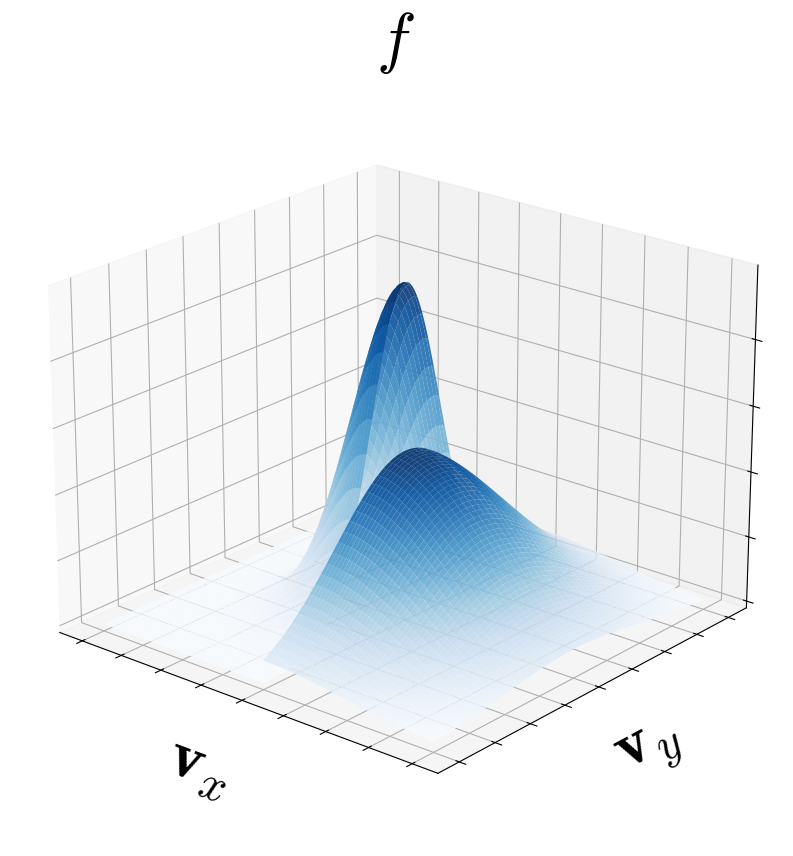

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# Configure Matplotlib to use its built-in MathText engine
plt.rcParams.update({
    "text.usetex": False,
    "mathtext.fontset": "cm"
})

# 1. Generate two separate coordinate grids to avoid artificial interpolation at the boundary
points = 150
v_negative = np.linspace(-4000, 0, points)
v_positive = np.linspace(0, 4000, points)
v_y_range = np.linspace(-4000, 4000, points * 2)

# Left Side: vx < 0 (1000 K Distribution)
vx_left, vy_left = np.meshgrid(v_negative, v_y_range)
v_sq_left = vx_left**2 + vy_left**2
z_1000 = (1 / 1000) * np.exp(-v_sq_left / (2 * 1000**2))

# Right Side: vx > 0 (2000 K Distribution)
vx_right, vy_right = np.meshgrid(v_positive, v_y_range)
v_sq_right = vx_right**2 + vy_right**2
z_2000 = (1 / 2000) * np.exp(-v_sq_right / (2 * 2000**2))

# 2. Build the combined 3D canvas
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

# Plot both halves using a single-color blue gradient
# shade=True adds subtle 3D lighting shadows to emphasize the cliff structure
surf1 = ax.plot_surface(vx_left, vy_left, z_1000, cmap='Blues', 
                        edgecolor='none', alpha=0.9, shade=True)

surf2 = ax.plot_surface(vx_right, vy_right, z_2000, cmap='Blues', 
                        edgecolor='none', alpha=0.9, shade=True)

# 3. Clean conceptual formatting (No numbers, large text labels)
ax.set_xlabel(r"$\mathbf{v}_x$", fontsize=48, labelpad=15)
ax.set_ylabel(r"$\mathbf{v}_y$", fontsize=48, labelpad=15)
ax.set_title(r"$f$", fontsize=48)

# Completely remove numerical labels/ticks from all three axes
ax.set_xticklabels([])
ax.set_yticklabels([])
ax.set_zticklabels([])

# Hide the small line tick marks to keep the grid completely smooth
ax.tick_params(axis='both', which='both', length=0)

# Set the same Z limits to keep the proportions visually true
max_z = z_1000.max()
ax.set_zlim(0, max_z)

# 4. View orientation to highlight the vertical cliff drop at vx = 0
ax.view_init(elev=22, azim=-50)

plt.tight_layout()
plt.show()
